

# AI Programming with Python Final Exam

**Name: Hamidul Hoque Masum**

**Course Email:**  hamidulhoquemasumcc@gmail.com




# 0) Starter Code (Run First)

In [2]:
# You must run this code and use this dataset for all questions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False)

# Question 01: [ Marks 10 ]

Use NumPy arrays from the score and attendance columns. Print both arrays and display:

* Data type
* Number of dimensions
* Shape
* Total number of elements

# Write Answer 01:


In [3]:
#score
sc=np.array(student_scores)
print(sc.dtype)
print(sc.ndim)
print(sc.shape)
print(sc.size)

int32
1
(50,)
50


In [4]:
#attendance
att=np.array(student_attendance)
print(att.dtype)
print(att.ndim)
print(att.shape)
print(att.size)

int32
1
(50,)
50


# Question 02: [ Marks 10 ]

## Using NumPy functions on :

* Find the maximum and minimum score
* Calculate the average score
* Calculate the average attendance

Then, extract students who:

* Have a score greater than the average score

Print:

* The filtered score array

## Write Answer 02:


In [5]:
sc=np.array(student_scores)

#max and min
print(sc.max())
print(sc.min())

#avg score
print(sc.mean())

99
41
67.3


In [6]:
#avg attendance
att=np.array(student_attendance)
print(att.mean())


79.58


In [7]:
#score greater than the average score
sc=np.array(student_scores)
greater_score=sc[sc>sc.mean()]
print(greater_score)

[76 90 78 99 89 97 92 86 99 83 86 74 75 89 79 93 81 93 68 83 73 75 70 87]


# Question 03: [Marks 10]

##
Load the school_data.csv file into a Pandas DataFrame.

* Display the first 3 rows
* Show dataset information using .info()
* Display summary statistics using .describe()

Then filter the dataset to include only:

* student_id, student_age, department, grade

Select students whose age is between 16 and 20, sort them by student_id, and display the last 3 rows of the result.


## Write Answer 03:

In [8]:
import pandas as pd
df=pd.read_csv('school_data.csv')
df.head(3)

,student_id,student_age,score,attendance,department,grade
0,201,21,76,73,Physics,B
1,202,18,90,82,Physics,A
2,203,19,46,99,Biology,F


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   student_id   50 non-null     int64
 1   student_age  50 non-null     int64
 2   score        50 non-null     int64
 3   attendance   50 non-null     int64
 4   department   50 non-null     str  
 5   grade        50 non-null     str  
dtypes: int64(4), str(2)
memory usage: 2.5 KB


In [10]:
df.describe()

,student_id,student_age,score,attendance
count,50.00000,50.000000,50.000000,50.000000
mean,225.50000,18.280000,67.300000,79.580000
std,14.57738,1.852081,18.248008,12.163998
min,201.00000,15.000000,41.000000,60.000000
25%,213.25000,17.000000,50.000000,68.000000
50%,225.50000,18.000000,66.000000,82.000000
75%,237.75000,20.000000,83.000000,91.000000
max,250.00000,21.000000,99.000000,99.000000


In [11]:
#filter dataset
filterd_data=df[['student_id','student_age','department','grade']]
filterd_data.head(3)

,student_id,student_age,department,grade
0,201,21,Physics,B
1,202,18,Physics,A
2,203,19,Biology,F


In [12]:
#age greater then 16 and less then 20
age_between_16_20=df[(df['student_age']>=16) & (df['student_age']<=20)]

#sort
age_between_16_20=age_between_16_20.sort_values('student_id')
age_between_16_20.head(3)

,student_id,student_age,score,attendance,department,grade
1,202,18,90,82,Physics,A
2,203,19,46,99,Biology,F
4,205,17,48,75,Economics,F



# Question 04: [ Marks 10 ]

##
Using .loc:

* Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
* Increase the score by 5% for all other departments
* Cap the score at 100 (no score should exceed 100 after the raise)

Then print a DataFrame that includes:

* student_id, department, previous_score, new_score, score_increase


## Write Answer 04:

In [13]:
import pandas as pd
df=pd.read_csv('school_data.csv')
#condition for cmt dept and math dept
cmt_math=df.loc[(df['department']=='Computer Science' )|
              (df['department']== 'Mathematics')].copy()
cmt_math.head(3)

,student_id,student_age,score,attendance,department,grade
8,209,16,64,84,Computer Science,C
9,210,17,99,88,Computer Science,A
10,211,21,53,74,Mathematics,C


**10% imcrease for cmt and math dept**

In [14]:
#increase 10% cmt and math
new_score=(cmt_math['score']*0.10)+cmt_math['score']
new_score
new_score=new_score.where(new_score<100,100)
cmt_math['score']=new_score
cmt_math.head(5)


,student_id,student_age,score,attendance,department,grade
8,209,16,70.4,84,Computer Science,C
9,210,17,100.0,88,Computer Science,A
10,211,21,58.3,74,Mathematics,C
13,214,19,52.8,66,Computer Science,F
20,221,20,100.0,76,Mathematics,A


**Increase 5% others dept**

In [15]:
#codition for other dept
other_dept=df.loc[(df['department']!='Computer Science' ) &
              (df['department']!= 'Mathematics')].copy()
other_dept_5=other_dept['score']*0.05+other_dept['score']
other_dept['score']=other_dept_5.where(other_dept_5<100,100)
other_dept.head(5)

,student_id,student_age,score,attendance,department,grade
0,201,21,79.8,73,Physics,B
1,202,18,94.5,82,Physics,A
2,203,19,48.3,99,Biology,F
3,204,21,63.0,80,Economics,C
4,205,17,50.4,75,Economics,F


In [16]:
#display student_id, department, previous_score, new_score, score_increase
new_df = pd.concat([cmt_math, other_dept]).sort_values('student_id')
new_df['previous_score']=df['score']
new_df['new_score']=new_df['score']
new_df['score_increase']=new_df['new_score']-new_df['previous_score']
new_df[['student_id','department','previous_score','new_score','score_increase']].head(5)


,student_id,department,previous_score,new_score,score_increase
0,201,Physics,76,79.8,3.8
1,202,Physics,90,94.5,4.5
2,203,Biology,46,48.3,2.3
3,204,Economics,60,63.0,3.0
4,205,Economics,48,50.4,2.4


# Question 05: [ Marks 10 ]

Using Matplotlib, create a bar chart that shows the average score per department.

* X-axis: Department names
* Y-axis: Average score
* Add a title: "Average Score by Department"
* Display the chart

## Answer 05:

Index(['Arts', 'Biology', 'Chemistry', 'Commerce', 'Computer Science',
       'Economics', 'English', 'Mathematics', 'Physics', 'Science'],
      dtype='str', name='department')
[70.         70.125      63.66666667 59.         67.83333333 58.66666667
 54.25       73.33333333 78.44444444 62.        ]


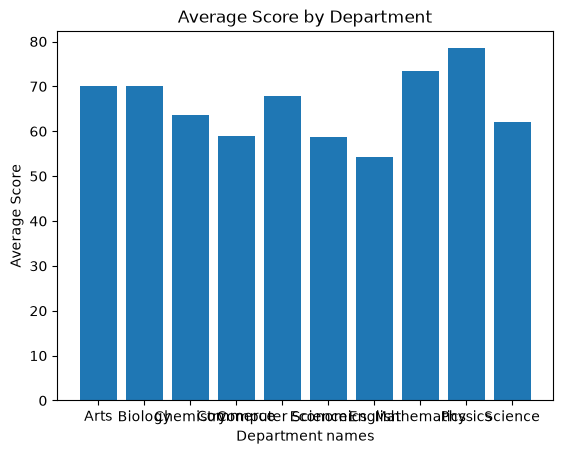

In [30]:
import matplotlib.pyplot as plt
df=pd.read_csv('school_data.csv')
avg_score=df.groupby('department')
avg_score=avg_score['score'].mean()
print(avg_score.index)
print(avg_score.values)
plt.bar(avg_score.index,avg_score.values)
plt.title('Average Score by Department')
plt.xlabel('Department names')
plt.ylabel('Average Score')
plt.show()

# Question 06: [ Marks 10 ]

Using Matplotlib, create a histogram of the score column.

* Use 10 bins
* Add a title: "Distribution of Student Scores"
* Label X-axis as "Score" and Y-axis as "Number of Students"
* Display the chart

## Answer 06:

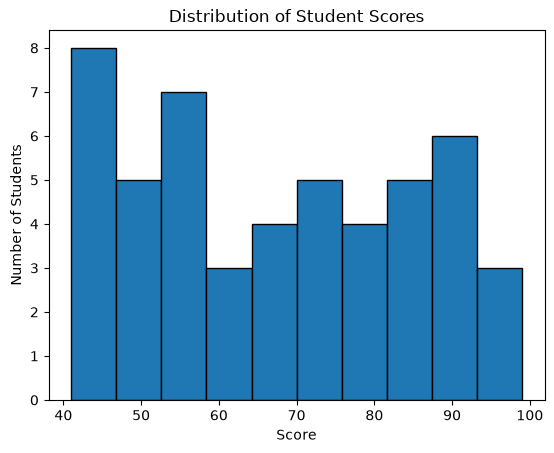

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
df=pd.read_csv('school_data.csv')
plt.hist(df['score'],edgecolor='black',bins=10)
plt.title('Distribution of Student Scores')
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.show()

# Question 07: [ Marks 10 ]

Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

* X-axis: Attendance (%)
* Y-axis: Score
* Add a title: "Attendance vs Score"
* Label both axes properly
* Display the chart

## Answer 07:


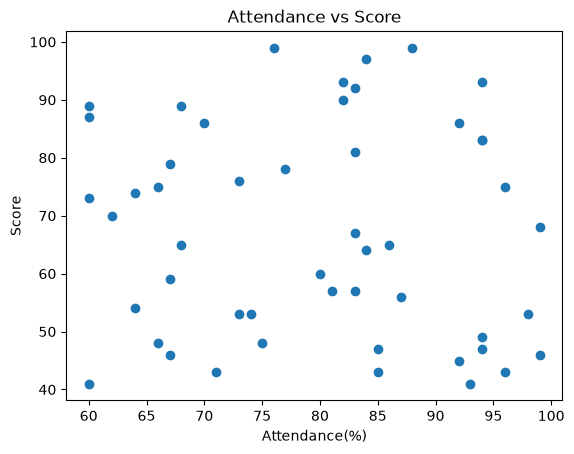

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
df=pd.read_csv('school_data.csv')
plt.scatter(x=df['attendance'],y=df['score'])
plt.title('Attendance vs Score')
plt.xlabel('Attendance(%)')
plt.ylabel('Score')
plt.show()

# Question 08: [ Marks 10 ]

Using Seaborn, create a boxplot / barplot that shows the distribution of score across different grade categories.

* X-axis: Grade
* Y-axis: Score
* Add a title: "Score Distribution by Grade"
* Display the chart

## Answer 08:

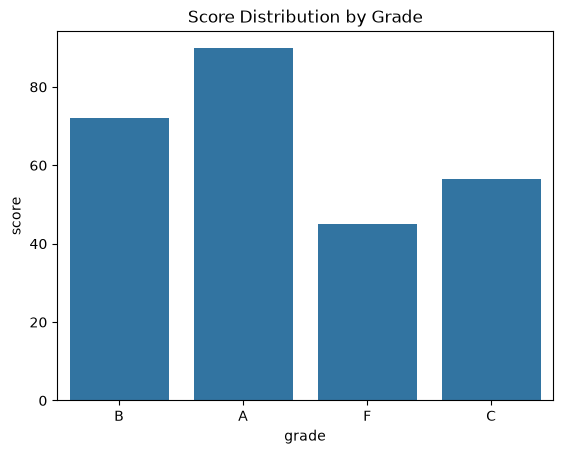

In [2]:
import seaborn as sns
import pandas as pd
df=pd.read_csv('school_data.csv')
sns.barplot(data=df,x='grade',y='score',errorbar=None)
plt.title('Score Distribution by Grade')
plt.show()

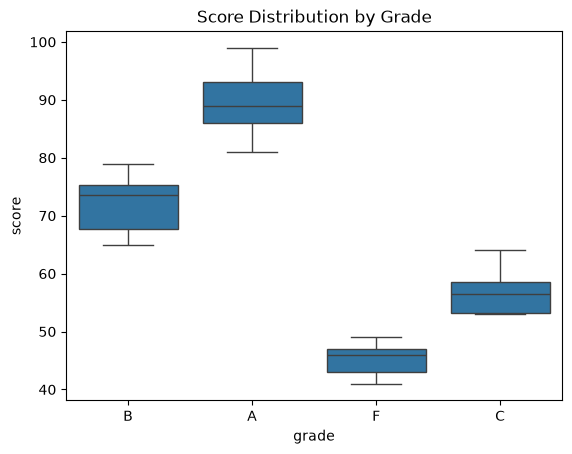

In [4]:
sns.boxplot(data=df,x='grade',y='score')
plt.title('Score Distribution by Grade')
plt.show()

# Question 09: [ Marks 10 ]

Using Seaborn, create a countplot showing the number of students in each department.

* Add a title: "Number of Students per Department"
* Display the chart

# Write Answer 09:

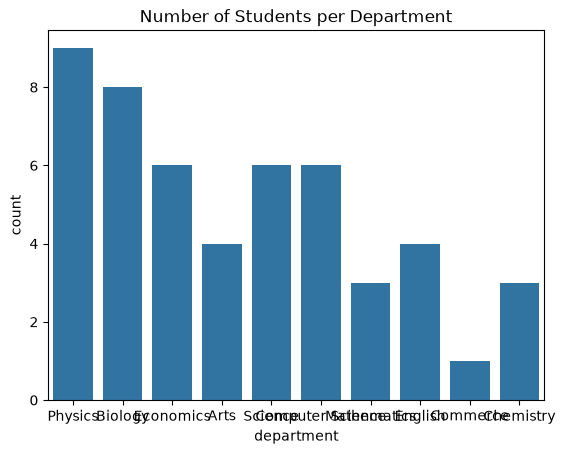

In [5]:
import seaborn as sns
import pandas as pd
df=pd.read_csv('school_data.csv')
sns.countplot(data=df,x='department')
plt.title('Number of Students per Department')
plt.show()

# Question 10: [ Marks 10 ]

create a scatter plot showing attendance vs score.

* Color the points by department
* Add a title: "Attendance vs Score by Department"
* Label X-axis as "Attendance (%)" and Y-axis as "Score"
* Display the chart

# Write Answer 10:

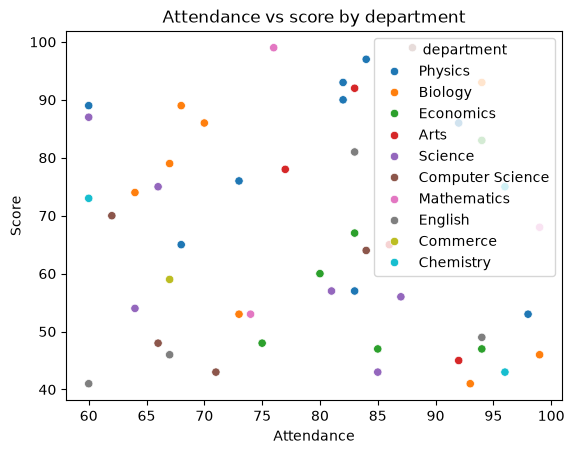

In [7]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('school_data.csv')
sns.scatterplot(data=df,x='attendance',y='score',hue='department')
plt.title('Attendance vs score by department')
plt.xlabel('Attendance')
plt.ylabel('Score')
plt.show()